<a href="https://colab.research.google.com/github/davidfwallace/metastase-pcam/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Análise exploratória e o "teste do atalho"

**Objetivo:** medir características simples de cada imagem (brilho, fração de pixels brancos, contraste, cor média) e responder: **quanto dá para acertar só com cor e brilho**, sem reconhecer a forma das células? O resultado é a régua mínima do projeto.

> Só treino e validação são usados. O teste continua fechado.

In [1]:
import io
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ_DADOS = Path("/content/drive/MyDrive/metastase-pcam")
else:
    RAIZ_DADOS = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = RAIZ_DADOS / "data"
REPORTS_DIR = RAIZ_DADOS / "reports"
FIG_DIR = REPORTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEMENTE = 42
POR_ARQUIVO = 2_000  # imagens sorteadas de cada arquivo de treino (13 arquivos -> ~26 mil)


def carregar(split, por_arquivo=None, semente=SEMENTE):
    """Lê os arquivos de um split; com `por_arquivo`, sorteia essa quantidade de cada arquivo."""
    partes = []
    for arquivo in sorted(DATA_DIR.rglob(f"{split}-*.parquet")):
        parte = pd.read_parquet(arquivo)
        if por_arquivo is not None:
            parte = parte.sample(min(por_arquivo, len(parte)), random_state=semente)
        partes.append(parte)
    return pd.concat(partes, ignore_index=True)


treino = carregar("train", POR_ARQUIVO)
valid = carregar("valid")
print(f"Treino (amostra): {len(treino):,} | validação: {len(valid):,}")
print(f"Fração com metástase — treino: {treino['label'].mean():.1%} | validação: {valid['label'].mean():.1%}")

Mounted at /content/drive
Treino (amostra): 26,000 | validação: 32,768
Fração com metástase — treino: 50.3% | validação: 50.0%


In [2]:
LIMIAR_BRANCO = 220  # em tons de cinza (0–255); o fundo da lâmina fica acima disso


def caracteristicas(imagem):
    """Medidas simples de cor e brilho de uma imagem (imagem inteira e região central 32×32)."""
    arr = np.asarray(Image.open(io.BytesIO(imagem["bytes"])), dtype=np.float32)  # (96, 96, 3)
    cinza = arr.mean(axis=2)
    centro = cinza[32:64, 32:64]
    return {
        "brilho": cinza.mean(),
        "fração branca": (cinza > LIMIAR_BRANCO).mean(),
        "brilho (centro)": centro.mean(),
        "fração branca (centro)": (centro > LIMIAR_BRANCO).mean(),
        "contraste": cinza.std(),
        "vermelho": arr[..., 0].mean(),
        "verde": arr[..., 1].mean(),
        "azul": arr[..., 2].mean(),
    }


c_treino = pd.DataFrame([caracteristicas(img) for img in treino["image"]])
c_treino["label"] = treino["label"].to_numpy()
c_valid = pd.DataFrame([caracteristicas(img) for img in valid["image"]])
c_valid["label"] = valid["label"].to_numpy()
CARACTERISTICAS = [c for c in c_treino.columns if c != "label"]

c_treino.groupby("label")[CARACTERISTICAS].mean().T.round(3)

label,False,True
brilho,168.480,159.609
fração branca,0.330,0.152
brilho (centro),168.385,159.144
fração branca (centro),0.328,0.142
contraste,46.910,44.833
vermelho,180.517,176.730
verde,146.059,128.244
azul,178.864,173.852


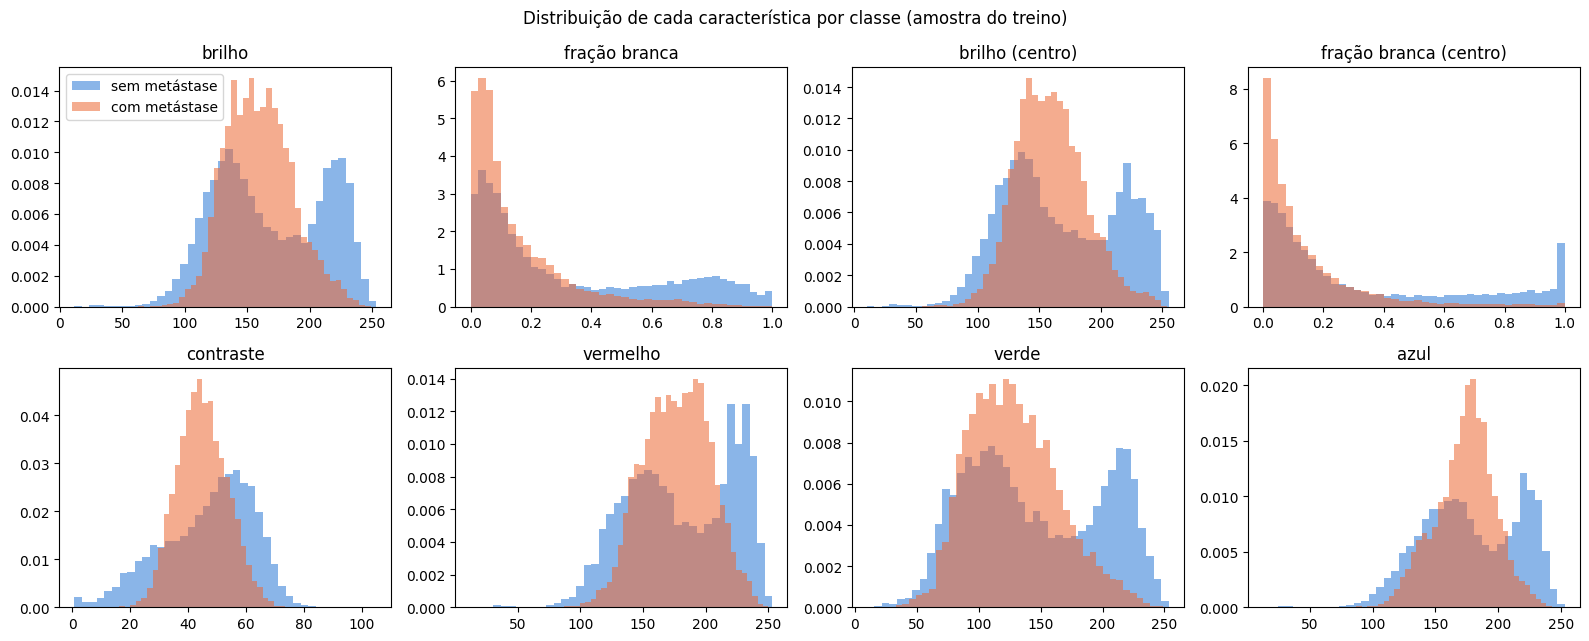

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, coluna in zip(axes.flat, CARACTERISTICAS):
    for rotulo, cor, nome in [(False, "#2a78d6", "sem metástase"), (True, "#eb6834", "com metástase")]:
        ax.hist(c_treino.loc[c_treino["label"] == rotulo, coluna], bins=40, alpha=0.55,
                color=cor, label=nome, density=True)
    ax.set_title(coluna)
axes.flat[0].legend()
fig.suptitle("Distribuição de cada característica por classe (amostra do treino)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_caracteristicas_por_classe.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_treino, y_valid = c_treino["label"], c_valid["label"]
linhas = []
for coluna in CARACTERISTICAS:
    # A direção (maior ou menor = mais metástase) é decidida no treino e aplicada na validação
    sinal = 1 if roc_auc_score(y_treino, c_treino[coluna]) >= 0.5 else -1
    linhas.append({"característica": coluna,
                   "direção": "maior → mais metástase" if sinal == 1 else "menor → mais metástase",
                   "ROC AUC (validação)": roc_auc_score(y_valid, sinal * c_valid[coluna])})

modelo_cor = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modelo_cor.fit(c_treino[CARACTERISTICAS], y_treino)
linhas.append({"característica": "regressão logística (as 8 juntas)", "direção": "—",
               "ROC AUC (validação)": roc_auc_score(y_valid, modelo_cor.predict_proba(c_valid[CARACTERISTICAS])[:, 1])})

atalho = pd.DataFrame(linhas).set_index("característica").sort_values("ROC AUC (validação)", ascending=False)
atalho.to_csv(REPORTS_DIR / "01_teste_do_atalho.csv", float_format="%.4f")
atalho.style.format({"ROC AUC (validação)": "{:.3f}"})

,direção,ROC AUC (validação)
característica,,
regressão logística (as 8 juntas),—,0.810
fração branca,menor → mais metástase,0.695
fração branca (centro),menor → mais metástase,0.684
verde,menor → mais metástase,0.628
brilho,menor → mais metástase,0.583
brilho (centro),menor → mais metástase,0.573
azul,menor → mais metástase,0.573
vermelho,menor → mais metástase,0.573
contraste,menor → mais metástase,0.487


**Conclusão:**

- **Régua do projeto: ROC AUC de 0,810** na validação, com uma regressão logística sobre 8 medidas simples de cor e brilho — sem nenhuma informação sobre a forma das células. As redes neurais precisam superá-la com folga; desempenho próximo indicaria um modelo apoiado em cor e fundo.
- **O atalho do fundo branco existe, mas é moderado:** a fração de pixels brancos sozinha dá ROC AUC de 0,695 (imagens sem metástase têm, em média, 33% de pixels brancos; com metástase, 15%).
- **Canal verde (0,628):** imagens com metástase têm menos verde — a coloração roxa dos núcleos absorve essa faixa. É um sinal ligado à densidade de núcleos, não só ao fundo.
- **Imagem inteira vs. centro:** a fração branca da imagem inteira (0,695) é ligeiramente mais informativa que a do centro (0,684), embora o rótulo dependa só do centro — o tecido ao redor também carrega informação.
- **Contraste (0,487):** sem poder preditivo como score único, porque a relação não é monotônica — os positivos se concentram em contrastes intermediários, e os negativos se espalham para os dois lados.
- **Duas "caras" dos negativos:** o brilho tem dois picos — tecido linfoide (~140) e fundo/gordura (~220).